# WaterTracker — Which reservoirs lose water faster than expected?
### Expected dry-season drawdown and detection of abnormal losses

**Question asked by managers.** "Which reservoirs lose their water clearly faster than evaporation and their usual behaviour explain, and should be visited first?"

**Why this question.** In the dry season a reservoir receives no inflow: its level falls through evaporation, seepage and withdrawals (irrigation, livestock, pumping). Evaporation follows the weather; a loss that the weather does not explain is worth a field visit.

**Hypothesis H6.** A model of the expected monthly drop, learned on the other reservoirs, isolates (a) reservoirs that lose water persistently faster than comparable ones and (b) seasons in which a reservoir loses water faster than it usually does.

**What this notebook cannot do.** There is no field record of withdrawals. A flag means "unexplained loss": it can be a withdrawal, seepage, a breach or a measurement error. The output is a list of reservoirs to check, not a proof. The detector is therefore validated by **injecting simulated withdrawals** into the real series (§6).

**Data.** The monthly panel produced by the main notebook (`data/gee/panel_monthly.parquet`): 100 water bodies × 92 months (January 2019 → August 2026), of which 96 can be modelled. The code is in `ml/withdrawals.py`; its tests are in `tests/test_withdrawals.py`.

> As in the main notebook, each step opens with the questions of the hydrologist 💧, the programmer 💻 and the AI engineer 🤖.

---
## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

BACKEND_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(BACKEND_DIR))
import ml.withdrawals as W

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
FIG_DIR = BACKEND_DIR / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_MODEL, C_CLIM, C_ALT, C_REF = "#2a78d6", "#6f6e69", "#eb6834", "#b9b8b3"
MONTHS = {1: "Nov", 2: "Dec", 3: "Jan", 4: "Feb", 5: "Mar"}
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.2


In [2]:
panel = pd.read_parquet(BACKEND_DIR / "data" / "gee" / "panel_monthly.parquet")
drops = W.monthly_drops(panel)
obs = drops[~drops.censored]
print(f"{len(drops)} dry-season monthly drops | {drops.reservoir_id.nunique()} reservoirs | "
      f"seasons {drops.season.min()}-{drops.season.max()}")
print(f"reservoir empty the following month (drop unknown, set aside): {drops.censored.mean():.1%}")
print(f"median drop of the level index: {obs.drop_mm.median():.0f} mm per month")
drops.groupby("step").size().rename(index=MONTHS).rename("monthly drops").to_frame().T

2240 dry-season monthly drops | 94 reservoirs | seasons 2018-2025
reservoir empty the following month (drop unknown, set aside): 7.7%
median drop of the level index: 835 mm per month


step,Nov,Dec,Jan,Feb,Mar
monthly drops,619,597,595,415,14


---
## 2. Monthly drops, and why a direct water balance is not enough

💧 *What is compared?* The satellite gives a water **area**. Evaporation removes a **depth** of water. The area is therefore converted into an equivalent depth with the area-volume relation of Liebe et al. (2005), V = k · A^b, which gives h = k · b / (b − 1) · A^(b − 1). This **level index** assumes an average basin shape: it is used to compare reservoirs and seasons, not to read true millimetres.

💻 A monthly drop is kept when both months are in the dry season (start in November to March), with less than 10 mm of rain, measured by Sentinel-2 at both dates, not flagged as outliers, and with enough water at the start (filling ≥ 10 % and area ≥ 1 ha). When the reservoir is empty the following month, the true drop is unknown and the month is set aside.

💧 *Can evaporation simply be subtracted?* If it could, the drop would be a stable share of the potential evaporation (PET, ERA5-Land).

Reservoir median of drop / PET: 10th-90th percentile 1.0 to 4.0


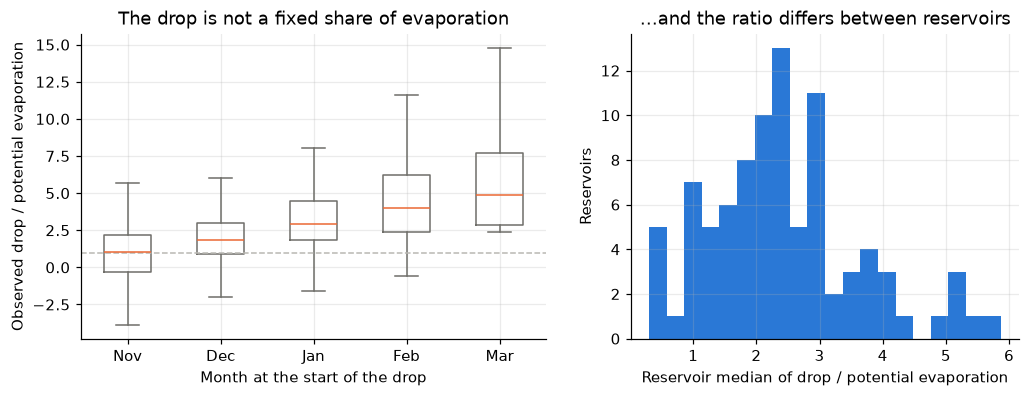

,drop_mm,pet_mm,ratio
step,,,
Nov,355.11,348.16,1.07
Dec,732.37,391.16,1.87
Jan,1174.41,405.86,2.90
Feb,1606.32,401.51,4.00
Mar,1937.69,385.78,4.85


In [3]:
ratio = obs.assign(ratio=obs.drop_mm / obs.pet_mm_mean)
by_month = ratio.groupby("step").agg(drop_mm=("drop_mm", "median"), pet_mm=("pet_mm_mean", "median"),
                                     ratio=("ratio", "median")).rename(index=MONTHS)
by_res = ratio.groupby("reservoir_id")["ratio"].agg(["median", "size"])
by_res = by_res[by_res["size"] >= W.MIN_MONTHS_CHRONIC]["median"]
print(f"Reservoir median of drop / PET: 10th-90th percentile {by_res.quantile(.1):.1f} to {by_res.quantile(.9):.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.boxplot([ratio.loc[ratio.step == s, "ratio"] for s in MONTHS], tick_labels=list(MONTHS.values()), showfliers=False,
            medianprops={"color": C_ALT}, boxprops={"color": C_CLIM}, whiskerprops={"color": C_CLIM}, capprops={"color": C_CLIM})
ax1.axhline(1, color=C_REF, ls="--", lw=1)
ax1.set_ylabel("Observed drop / potential evaporation")
ax1.set_xlabel("Month at the start of the drop")
ax1.set_title("The drop is not a fixed share of evaporation")
ax2.hist(by_res, bins=20, color=C_MODEL)
ax2.set_xlabel("Reservoir median of drop / potential evaporation")
ax2.set_ylabel("Reservoirs")
ax2.set_title("…and the ratio differs between reservoirs")
fig.savefig(FIG_DIR / "fig20_withdrawals_drop_vs_pet.png")
plt.show()
by_month.round(2)

💧 *Reading:* the drop of the level index is about equal to the potential evaporation in November, then grows to four to five times as much in February and March, and the ratio ranges from 1 to 4 between reservoirs. Part of this is real (seepage, and irrigation and livestock demand that grow as the dry season advances), part comes from the assumed basin shape, which exaggerates the drop when the reservoir is low. The two cannot be separated with a surface measurement alone. **Subtracting evaporation and calling the rest "withdrawals" would flag every reservoir.** The expected drop is therefore learned from comparable reservoirs, month by month.

---
## 3. The expected drop: a model learned on the other reservoirs

🤖 *What is "expected"?* The drop that comparable reservoirs show in the same conditions: potential evaporation of the two months, month of the season, filling ratio, level index, reservoir size and seasonal peak. A gradient-boosting model predicts the **median** drop (absolute-error loss), which is not pulled by the abnormal months it is meant to reveal.

💻 *No reservoir is its own reference.* Reservoirs are split into five groups; each reservoir's expected drop comes from a model trained without its group (`W.PeerModel`). The **excess** is the observed drop minus the expected drop.

In [4]:
model = W.PeerModel().fit(drops)
scored = W.add_excess(drops, model)
s = scored[~scored.censored]


def scores(pred):
    err = (s.drop_mm - pred).abs()
    return {"MAE (mm)": err.mean(), "median error (mm)": err.median(),
            "R²": 1 - ((s.drop_mm - pred) ** 2).sum() / ((s.drop_mm - s.drop_mm.mean()) ** 2).sum()}


table = pd.DataFrame({
    "Same drop everywhere (median)": scores(s.drop_mm.median()),
    "Median drop of the month": scores(s.groupby("step").drop_mm.transform("median")),
    "Peer model (reservoir never seen)": scores(s.expected_mm),
}).T
print(f"Spread of the excess (robust sd): {W.robust_sd(s.excess_mm):.0f} mm per month")
table.round({"MAE (mm)": 0, "median error (mm)": 0, "R²": 2})

Spread of the excess (robust sd): 691 mm per month


,MAE (mm),median error (mm),R²
Same drop everywhere (median),792.0,568.0,-0.03
Median drop of the month,692.0,489.0,0.22
Peer model (reservoir never seen),656.0,475.0,0.31


🤖 *Reading:* the peer model is better than the references (mean error 656 mm against 692 mm for the median of the month), but it explains only about a third of the variance (R² 0.31). A single monthly drop is noisy: the spread of the excess (about 690 mm) is close to the typical drop itself (835 mm). **One month alone proves nothing**; the two readings below therefore aggregate several months.

---
## 4. Chronic reading: reservoirs that always lose water faster than their peers

💧 For each reservoir with at least six valid months, the median excess over all seasons is compared with the other reservoirs (robust z-score). A reservoir is flagged when z ≥ 2.5.

🤖 *Is it a real trait or noise?* If it is real, the ranking obtained on seasons 2018-2021 must be found again on seasons 2022-2025.

90 reservoirs with at least 6 valid months | flagged (z ≥ 2.5): 3
Stability 2018-2021 vs 2022-2025: Spearman 0.72 on 78 reservoirs


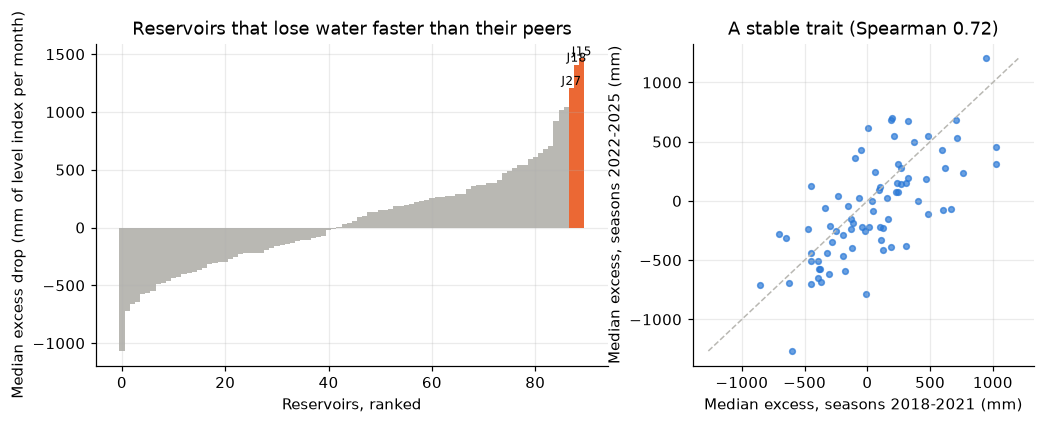

,reservoir_id,n_months,a_ref_ha,drop_mm,expected_mm,excess_mm,ratio,z,flag
0,J15,7,37.1,2213.0,749.0,1464.0,2.95,3.26,True
1,J18,7,32.5,2187.0,799.0,1410.0,2.74,3.14,True
2,J27,11,26.4,2261.0,656.0,1209.0,3.45,2.67,True
3,J41,8,15.6,1530.0,737.0,1046.0,2.08,2.30,False
4,J13,15,40.4,1748.0,839.0,1018.0,2.08,2.23,False
5,J10,17,59.2,1768.0,422.0,918.0,4.19,2.00,False
6,R01,32,6524.2,2223.0,1726.0,703.0,1.29,1.51,False
7,J06,23,55.8,2140.0,1297.0,682.0,1.65,1.46,False


In [5]:
reservoirs = W.chronic(scored)
early = W.chronic(scored[scored.season <= 2021]).set_index("reservoir_id")["excess_mm"]
late = W.chronic(scored[scored.season >= 2022]).set_index("reservoir_id")["excess_mm"]
both = pd.concat([early.rename("early"), late.rename("late")], axis=1).dropna()
rho = both.corr(method="spearman").iloc[0, 1]
print(f"{len(reservoirs)} reservoirs with at least {W.MIN_MONTHS_CHRONIC} valid months | flagged (z ≥ {W.Z_CHRONIC}): {reservoirs.flag.sum()}")
print(f"Stability 2018-2021 vs 2022-2025: Spearman {rho:.2f} on {len(both)} reservoirs")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
r = reservoirs.sort_values("excess_mm").reset_index(drop=True)
ax1.bar(r.index, r.excess_mm, color=np.where(r.flag, C_ALT, C_REF), width=1.0)
ax1.set_xlabel("Reservoirs, ranked")
ax1.set_ylabel("Median excess drop (mm of level index per month)")
ax1.set_title("Reservoirs that lose water faster than their peers")
for _, row in r[r.flag].iterrows():
    ax1.annotate(row.reservoir_id, (row.name, row.excess_mm), ha="center", va="bottom", fontsize=8)
flagged = both.index.isin(reservoirs.loc[reservoirs.flag, "reservoir_id"])
ax2.scatter(both.early[~flagged], both.late[~flagged], s=14, color=C_MODEL, alpha=0.7)
ax2.scatter(both.early[flagged], both.late[flagged], s=30, color=C_ALT)
lim = [both.min().min(), both.max().max()]
ax2.plot(lim, lim, color=C_REF, ls="--", lw=1)
ax2.set_xlabel("Median excess, seasons 2018-2021 (mm)")
ax2.set_ylabel("Median excess, seasons 2022-2025 (mm)")
ax2.set_title(f"A stable trait (Spearman {rho:.2f})")
fig.savefig(FIG_DIR / "fig21_withdrawals_chronic.png")
plt.show()
reservoirs.head(8).round({"a_ref_ha": 1, "drop_mm": 0, "expected_mm": 0, "excess_mm": 0, "ratio": 2, "z": 2})

💧 *Reading:* three reservoirs out of 90 are flagged (J15, J18, J27): their level index falls two to three and a half times faster than expected for reservoirs of their size in the same conditions. The ranking is stable: reservoirs with a high excess in 2018-2021 have a high excess in 2022-2025 (Spearman 0.72). The fast loss is therefore a **lasting property of these reservoirs**, not noise. It can be a heavy and regular use, strong seepage, or a basin much shallower than the average shape assumed here: only a visit can tell.

---
## 5. Episodic reading: a season faster than usual

💧 For each reservoir and season with at least two valid months, the mean excess of the season is compared with the usual excess of the **same reservoir in its other seasons** (at the same month when there is enough history). The difference is divided by its spread over all reservoir-seasons with the same number of months. A season is flagged when z ≥ 3.

🤖 *How many flags are due to chance?* Noise is as likely to make a season look slow as fast. The number of seasons in the opposite tail (z ≤ −3) is therefore an estimate of the false alarms among the flags.

609 reservoir-seasons scored | flagged (z ≥ 3.0): 21 (3.4%), in 16 reservoirs


,flagged (z ≥ threshold),opposite tail (z ≤ −threshold)
threshold,,
2.0,47,30
2.5,28,17
3.0,21,4


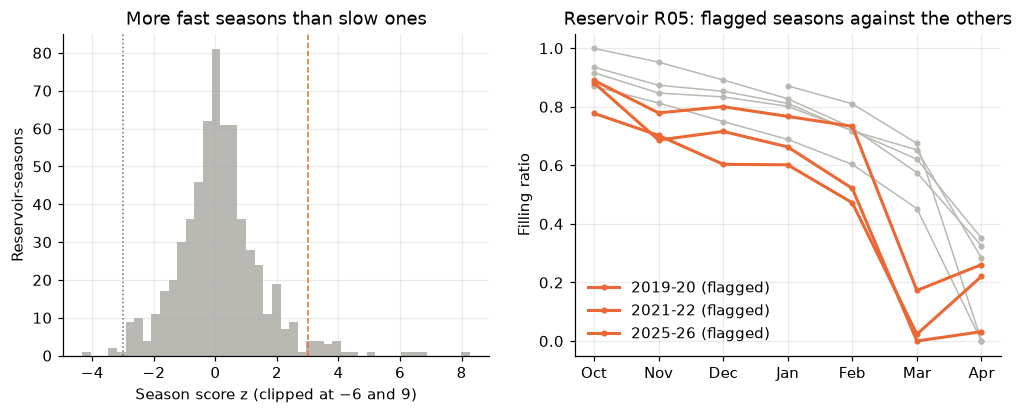

,reservoir_id,season,n_months,excess_mm,usual_excess_mm,drop_mm,expected_mm,deviation_mm,z,flag
0,R05,2019,4,2019.0,-404.0,3221.0,1202.0,2422.0,8.3,True
1,J02,2023,3,1798.0,-140.0,3312.0,1514.0,1938.0,6.7,True
2,R34,2020,3,1649.0,-253.0,2273.0,624.0,1903.0,6.6,True
3,R05,2021,4,1351.0,-434.0,2574.0,1223.0,1785.0,6.1,True
4,R04,2022,3,1521.0,91.0,2274.0,753.0,1431.0,4.9,True
5,J02,2020,3,1181.0,-155.0,2675.0,1495.0,1336.0,4.6,True
6,R23,2020,4,-147.0,-1364.0,1411.0,1559.0,1217.0,4.2,True
7,J04,2025,2,2075.0,151.0,3106.0,1030.0,1925.0,4.1,True
8,J36,2019,2,1946.0,56.0,2353.0,407.0,1889.0,4.0,True
9,J05,2018,2,1809.0,-28.0,2750.0,940.0,1837.0,3.9,True


In [6]:
seasons = W.episodic(scored)
scale = W.deviation_scale(seasons)
tails = pd.DataFrame({z: {"flagged (z ≥ threshold)": (seasons.z >= z).sum(),
                          "opposite tail (z ≤ −threshold)": (seasons.z <= -z).sum()} for z in (2.0, 2.5, 3.0)}).T
tails.index.name = "threshold"
print(f"{len(seasons)} reservoir-seasons scored | flagged (z ≥ {W.Z_EPISODIC}): {seasons.flag.sum()} "
      f"({seasons.flag.mean():.1%}), in {seasons[seasons.flag].reservoir_id.nunique()} reservoirs")
display(tails)

top = seasons.iloc[0]
curve = W.prepare(panel)
curve = curve[(curve.reservoir_id == top.reservoir_id) & curve.step.between(0, 6)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(seasons.z.clip(-6, 9), bins=45, color=C_REF)
ax1.axvline(W.Z_EPISODIC, color=C_ALT, ls="--", lw=1)
ax1.axvline(-W.Z_EPISODIC, color=C_CLIM, ls=":", lw=1)
ax1.set_xlabel("Season score z (clipped at −6 and 9)")
ax1.set_ylabel("Reservoir-seasons")
ax1.set_title("More fast seasons than slow ones")
flagged_seasons = set(seasons[(seasons.reservoir_id == top.reservoir_id) & seasons.flag].season)
for season, g in curve.groupby("season"):
    hit = season in flagged_seasons
    ax2.plot(g.step, g.fill, color=C_ALT if hit else C_REF, lw=2 if hit else 1, marker="o", ms=3,
             label=f"{season}-{(season + 1) % 100:02d} (flagged)" if hit else None, zorder=3 if hit else 2)
ax2.set_xticks(range(0, 7), ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
ax2.set_ylabel("Filling ratio")
ax2.set_title(f"Reservoir {top.reservoir_id}: flagged seasons against the others")
ax2.legend(frameon=False)
fig.savefig(FIG_DIR / "fig22_withdrawals_episodic.png")
plt.show()
seasons[seasons.flag].round({"excess_mm": 0, "usual_excess_mm": 0, "drop_mm": 0, "expected_mm": 0, "deviation_mm": 0, "z": 1})

💧 *Reading:* 21 reservoir-seasons out of 609 are flagged (3.4 %), in 16 reservoirs, against 4 in the opposite tail: roughly four flags in five are more than chance. Some reservoirs come back several times (R05 in three seasons, J02, J04 and R02 in two). The right-hand panel shows the reservoir with the highest score: in its flagged seasons the filling ratio falls well before the other years. These seasons are the first candidates for a check against field knowledge (new irrigated plot, pumping, works on the dam).

---
## 6. Validation by injection: how large must a withdrawal be to be seen?

🤖 *Without field data, how can the detector be tested?* Withdrawals are simulated in real series that are not flagged, and the detector is asked to find them again. A simulated withdrawal lowers the level index by a fixed amount each month from November, expressed as a share of the typical monthly drop; area and filling are recomputed.

- **One season** (100 reservoir-seasons): is the season flagged by the episodic reading?
- **Every season** (40 reservoirs): is the reservoir flagged by the chronic reading?

💧 A strong withdrawal empties the reservoir early: fewer valid months remain and the season can no longer be scored. Those cases are counted as not detected here; they are the ones the drying-month forecast (`ml/drying.py`) is designed to catch.

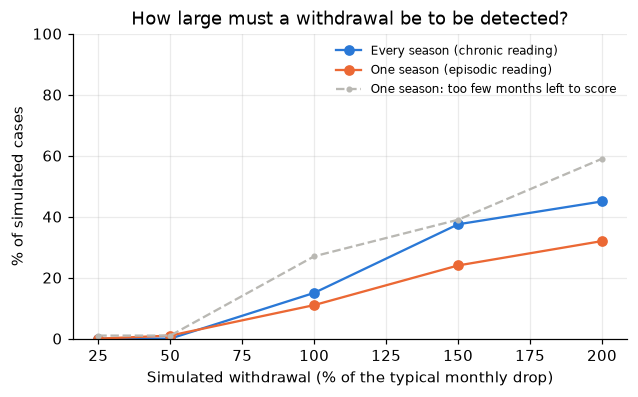

,extra_mm,season: detected,season: no longer scorable,reservoir: detected,reservoir: no longer scorable
extra loss,,,,,
+25%,209,0.00,0.01,0.00,0.00
+50%,418,0.01,0.01,0.00,0.00
+100%,835,0.11,0.27,0.15,0.02
+150%,1253,0.24,0.39,0.38,0.25
+200%,1670,0.32,0.59,0.45,0.40


In [7]:
typical = s.drop_mm.median()
LEVELS = [0.25, 0.5, 1.0, 1.5, 2.0]          # extra loss, as a share of the typical monthly drop


def season_z(rid, season, extra_mm):
    """Score of one reservoir-season after a simulated withdrawal (NaN if it can no longer be scored)."""
    d = W.monthly_drops(W.inject_withdrawal(panel[panel.reservoir_id == rid], rid, season, extra_mm))
    if d.empty:
        return np.nan
    out = W.episodic(W.add_excess(d, model), scale=scale)
    out = out[out.season == season]
    return out.z.iloc[0] if len(out) else np.nan


def reservoir_z(rid, extra_mm):
    """Chronic score of one reservoir after the same withdrawal every season."""
    sub = panel[panel.reservoir_id == rid]
    for season in range(int(drops.season.min()), int(drops.season.max()) + 1):
        sub = W.inject_withdrawal(sub, rid, season, extra_mm)
    d = W.monthly_drops(sub)
    if d.empty:
        return np.nan
    out = W.chronic(pd.concat([scored[scored.reservoir_id != rid], W.add_excess(d, model)]))
    out = out[out.reservoir_id == rid]
    return out.z.iloc[0] if len(out) else np.nan


quiet_seasons = seasons[seasons.z < 2].sample(100, random_state=SEED)
quiet_reservoirs = reservoirs[reservoirs.z < 1.5].sample(40, random_state=SEED)
rows = []
for share in LEVELS:
    z_s = np.array([season_z(r.reservoir_id, r.season, share * typical) for r in quiet_seasons.itertuples()])
    z_r = np.array([reservoir_z(rid, share * typical) for rid in quiet_reservoirs.reservoir_id])
    rows.append({"extra loss": f"+{share:.0%}", "extra_mm": round(share * typical),
                 "season: detected": np.mean(np.nan_to_num(z_s, nan=-99) >= W.Z_EPISODIC),
                 "season: no longer scorable": np.isnan(z_s).mean(),
                 "reservoir: detected": np.mean(np.nan_to_num(z_r, nan=-99) >= W.Z_CHRONIC),
                 "reservoir: no longer scorable": np.isnan(z_r).mean()})
injection = pd.DataFrame(rows).set_index("extra loss")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = [100 * v for v in LEVELS]
ax.plot(x, 100 * injection["reservoir: detected"], color=C_MODEL, marker="o", label="Every season (chronic reading)")
ax.plot(x, 100 * injection["season: detected"], color=C_ALT, marker="o", label="One season (episodic reading)")
ax.plot(x, 100 * injection["season: no longer scorable"], color=C_REF, ls="--", marker=".", label="One season: too few months left to score")
ax.set_xlabel("Simulated withdrawal (% of the typical monthly drop)")
ax.set_ylabel("% of simulated cases")
ax.set_ylim(0, 100)
ax.set_title("How large must a withdrawal be to be detected?")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG_DIR / "fig23_withdrawals_injection.png")
plt.show()
injection.round(2)

🤖 *Reading:* sensitivity is low. A withdrawal that adds a quarter or a half to the normal loss is never found. A withdrawal that **doubles** the normal loss is found in about one case in ten for a single season and one in seven when it is repeated every season; at three times the normal loss, about one in three and one in two. Many strong cases are lost because the reservoir empties and too few months remain to score it. With one surface measurement per month, **only massive losses can be detected, and most of them are still missed**.

---
## 7. Conclusion

**Answer to H6 (values of this run, see the tables above): partly supported.**
- A direct water balance does not work with these data: the measured drop is one to five times the potential evaporation depending on the month and the reservoir (§2). The expected drop has to be learned from comparable reservoirs.
- **Chronic reading: supported.** The excess loss of a reservoir is a stable trait (Spearman 0.72 between 2018-2021 and 2022-2025). Three reservoirs out of 90 stand out clearly: J15, J18 and J27.
- **Episodic reading: supported with a low sensitivity.** 21 seasons are flagged against about 4 expected by chance, so most flags are real unexplained losses. But the injection test shows that a withdrawal must at least double the normal loss to have a chance of being found, and that most simulated withdrawals are missed.
- A flag is an **unexplained loss**, not a proven withdrawal. Nothing here separates withdrawals from seepage, a breach, a shallow basin or a measurement error.

**Operational use.** `W.detect(panel)` returns the two lists. They are best presented as **"reservoirs to check first"**: a short list, few false alarms, and no claim that an unflagged reservoir is free of withdrawals.

**What would improve it.**
- Field data, even a few dozen cases (known irrigated perimeters, pumping records), to measure true and false alarms instead of simulating them.
- A measured depth-area curve per reservoir, to replace the average basin shape and make a real water balance possible.
- More frequent surface measurements (every 5 to 10 days instead of monthly), which would reduce the noise of each drop and catch short episodes.